# FinSurvival – Kiểm tra dữ liệu task **Borrow → Liquidated**

Notebook này kiểm tra dữ liệu và tạo nhãn phân loại, chưa huấn luyện mô hình.

**Cách dùng**
1. Đặt file này vào thư mục gốc của repo: `D:\BlockChain\DMLR_DeFi_Survival_Benchmark\` (cùng chỗ với `dataLoader.R`).
2. Cài thư viện: `pip install pyreadr pandas pyarrow matplotlib`
3. Chạy lần lượt từng ô (hoặc *Run All*).

Nếu đã chạy `inspect_borrow_liquidated.py` trước đó, notebook sẽ đọc thẳng các file `.parquet` trong `processed/` cho nhanh. Nếu chưa, nó tự đọc file `.rds` và lưu lại parquet.

**Số liệu tham chiếu từ bài báo (Bảng 4, 5):** 264.536 bản ghi survival, 83,42% bị censor; sau khi tạo nhãn còn 255.209 dòng, lớp 1 chiếm 4,77%; ngưỡng RMST = 17,43 ngày.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

BASE = os.path.join("Data", "Survival_Data", "Borrow")
PROCESSED = "processed"
RMST_DAYS = 17.43                      # ngưỡng của bài báo cho Borrow -> Liquidated (Bảng 5)
T = RMST_DAYS * 86400                  # đổi sang giây vì timeDiff tính bằng giây
print("Ngưỡng T =", int(T), "giây")

Ngưỡng T = 1505952 giây


## 1. Load dữ liệu

In [2]:
def read_rds(path):
    import pyreadr
    return next(iter(pyreadr.read_r(path).values()))


def load_parts(folder, prefix):
    files = glob.glob(os.path.join(BASE, folder, f"{prefix}_*.rds"))
    files.sort(key=lambda p: int(p.rsplit("_", 1)[1].split(".")[0]))
    return pd.concat([read_rds(f) for f in files], ignore_index=True)


pq = {k: os.path.join(PROCESSED, f"{k}.parquet")
      for k in ["X_train", "X_test", "y_train_liquidated", "y_test_liquidated"]}

if all(os.path.exists(p) for p in pq.values()):
    print("Đọc từ parquet...")
    X_train = pd.read_parquet(pq["X_train"])
    X_test = pd.read_parquet(pq["X_test"])
    y_train = pd.read_parquet(pq["y_train_liquidated"])
    y_test = pd.read_parquet(pq["y_test_liquidated"])
else:
    print("Đọc từ .rds (lần đầu sẽ hơi lâu)...")
    liq = [d for d in os.listdir(BASE) if "iquidat" in d.lower()]
    assert liq, "Không thấy thư mục liquidated trong Data/Survival_Data/Borrow"
    X_train = load_parts("X_train", "X_train")
    X_test = load_parts("X_test", "X_test")
    y_train = read_rds(os.path.join(BASE, liq[0], "y_train.rds"))
    y_test = read_rds(os.path.join(BASE, liq[0], "y_test.rds"))
    os.makedirs(PROCESSED, exist_ok=True)
    X_train.to_parquet(pq["X_train"]); X_test.to_parquet(pq["X_test"])
    y_train.to_parquet(pq["y_train_liquidated"]); y_test.to_parquet(pq["y_test_liquidated"])

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)

Đọc từ parquet...
X_train: (161826, 129) | y_train: (161826, 5)
X_test : (98060, 129) | y_test : (102710, 5)


## 2. Tổng quan y

- `timeDiff`: số giây từ lúc vay đến lúc bị thanh lý, hoặc đến thời điểm cuối được quan sát nếu không bị thanh lý
- `status`: 1 = bị thanh lý, 0 = bị censor (chưa thấy thanh lý)
- `id`: mã giao dịch vay, dùng để nối với X
- `Index Event`, `Outcome Event`: hằng số, chỉ để ghi chú

In [3]:
display(y_train.head())
print(y_train.dtypes)
print("\nGiá trị duy nhất của Index Event  :", y_train["Index Event"].unique())
print("Giá trị duy nhất của Outcome Event:", y_train["Outcome Event"].unique())

,timeDiff,status,id,Index Event,Outcome Event
0,49806576.0,0.0,0xc70f4c3f447f6a88e9fbb87ac1394b589e469ee57dda...,borrow,account liquidated
1,49746136.0,0.0,0x1ee3db904548c16d2ed3572f3d9894652e031facc8fa...,borrow,account liquidated
2,49743104.0,0.0,0x1e8f85330edc5005ead7a7ae8c418fbb64df726d4ffc...,borrow,account liquidated
3,49734553.0,0.0,0x43136c7aba13c072bb19ed88f8eadf859f0bfb994b42...,borrow,account liquidated
4,49733175.0,0.0,0xd96af0cf05a1e99125fe51ee7e27a1c96cf40ea6e596...,borrow,account liquidated


timeDiff         float64
status           float64
id                object
Index Event       object
Outcome Event     object
dtype: object

Giá trị duy nhất của Index Event  : ['borrow']
Giá trị duy nhất của Outcome Event: ['account liquidated']


,train,test
số dòng,161826.00,102710.0
status=1 (bị thanh lý),37683.00,6159.0
status=0 (censor),124143.00,96551.0
% censor,76.71,94.0


Gộp train+test: 264,536 dòng | % censor = 83.43%  (bài báo: 264.536 dòng, 83,42%)


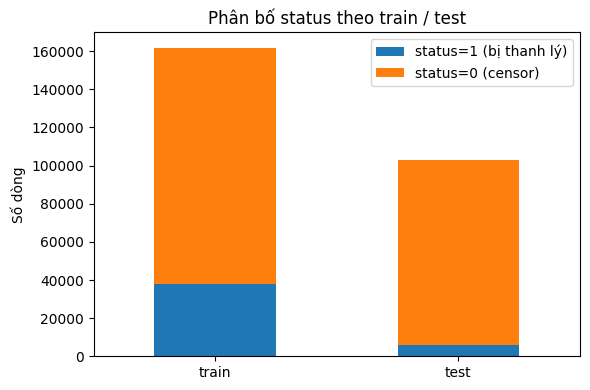

In [4]:
summary = pd.DataFrame({
    split: {
        "số dòng": len(y),
        "status=1 (bị thanh lý)": int((y["status"] == 1).sum()),
        "status=0 (censor)": int((y["status"] == 0).sum()),
        "% censor": round(100 * (y["status"] == 0).mean(), 2),
    }
    for split, y in [("train", y_train), ("test", y_test)]
})
display(summary)

all_y = pd.concat([y_train, y_test])
print(f"Gộp train+test: {len(all_y):,} dòng | % censor = {100 * (all_y['status'] == 0).mean():.2f}%  (bài báo: 264.536 dòng, 83,42%)")

ax = summary.loc[["status=1 (bị thanh lý)", "status=0 (censor)"]].T.plot.bar(stacked=True, figsize=(6, 4), rot=0)
ax.set_title("Phân bố status theo train / test"); ax.set_ylabel("Số dòng")
plt.tight_layout(); plt.show()

## 3. Phân bố thời gian `timeDiff`

Quan trọng nhất là: trong các khoản vay **bị thanh lý**, bao nhiêu khoản bị thanh lý **trong vòng 17,43 ngày**.

== train ==
  timeDiff (ngày) - toàn bộ  : {'min': 0.0, '50%': 281.1, 'mean': 257.5, 'max': 576.5}
  timeDiff (ngày) - bị thanh lý: {'min': 0.0, '50%': 44.8, 'mean': 90.8, 'max': 564.2}
  Bị thanh lý trong <= 17.43 ngày: 10,889 / 37,683 (28.9%)

== test ==
  timeDiff (ngày) - toàn bộ  : {'min': 0.0, '50%': 483.9, 'mean': 426.9, 'max': 689.3}
  timeDiff (ngày) - bị thanh lý: {'min': 0.0, '50%': 68.5, 'mean': 104.5, 'max': 678.3}
  Bị thanh lý trong <= 17.43 ngày: 1,273 / 6,159 (20.7%)



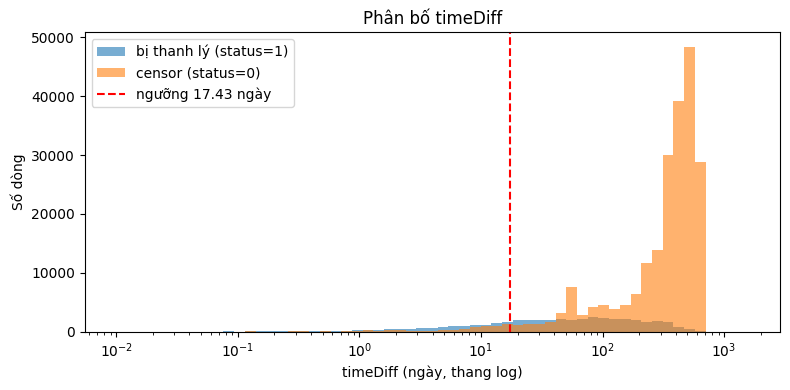

In [5]:
for split, y in [("train", y_train), ("test", y_test)]:
    days = y["timeDiff"] / 86400
    liq_days = days[y["status"] == 1]
    print(f"== {split} ==")
    print("  timeDiff (ngày) - toàn bộ  :", days.describe()[["min", "50%", "mean", "max"]].round(1).to_dict())
    print("  timeDiff (ngày) - bị thanh lý:", liq_days.describe()[["min", "50%", "mean", "max"]].round(1).to_dict())
    print(f"  Bị thanh lý trong <= {RMST_DAYS} ngày: {(liq_days <= RMST_DAYS).sum():,} / {len(liq_days):,} "
          f"({100 * (liq_days <= RMST_DAYS).mean():.1f}%)\n")

fig, ax = plt.subplots(figsize=(8, 4))
for s, lbl in [(1, "bị thanh lý (status=1)"), (0, "censor (status=0)")]:
    d = all_y.loc[all_y["status"] == s, "timeDiff"] / 86400
    ax.hist(d.clip(lower=0.01), bins=np.logspace(-2, 3.2, 60), alpha=0.6, label=lbl)
ax.axvline(RMST_DAYS, color="red", ls="--", label=f"ngưỡng {RMST_DAYS} ngày")
ax.set_xscale("log"); ax.set_xlabel("timeDiff (ngày, thang log)"); ax.set_ylabel("Số dòng")
ax.set_title("Phân bố timeDiff"); ax.legend(); plt.tight_layout(); plt.show()

## 4. Tạo nhãn phân loại

| Điều kiện | Nhãn |
|---|---|
| `status = 1` và `timeDiff ≤ T` | **1** (bị thanh lý sớm) |
| `timeDiff > T` | **0** |
| `status = 0` và `timeDiff ≤ T` | **bỏ** (chưa đủ thời gian quan sát) |

In [6]:
def make_label(y, T=T):
    label = pd.Series(np.nan, index=y.index)
    label[(y["status"] == 1) & (y["timeDiff"] <= T)] = 1
    label[y["timeDiff"] > T] = 0
    return label


y_train["label"] = make_label(y_train)
y_test["label"] = make_label(y_test)

rows = []
for split, y in [("train", y_train), ("test", y_test)]:
    kept = y["label"].notna()
    rows.append({"split": split, "ban đầu": len(y), "bị bỏ": int((~kept).sum()),
                 "giữ lại": int(kept.sum()), "lớp 1": int((y["label"] == 1).sum()),
                 "% lớp 1": round(100 * y.loc[kept, "label"].mean(), 2)})
label_table = pd.DataFrame(rows).set_index("split")
label_table.loc["tổng"] = label_table.sum()
label_table.loc["tổng", "% lớp 1"] = round(100 * label_table.loc["tổng", "lớp 1"] / label_table.loc["tổng", "giữ lại"], 2)
display(label_table)
print("Bài báo: 255.209 dòng, lớp 1 = 4,77%")

,ban đầu,bị bỏ,giữ lại,lớp 1,% lớp 1
split,,,,,
train,161826.0,4185.0,157641.0,10889.0,6.91
test,102710.0,1912.0,100798.0,1273.0,1.26
tổng,264536.0,6097.0,258439.0,12162.0,4.71


Bài báo: 255.209 dòng, lớp 1 = 4,77%


## 5. Nối X với y bằng `id`

In [7]:
for split, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
    print(f"== {split} ==")
    print("  id trong X duy nhất :", X["id"].is_unique, "| id trong y duy nhất:", y["id"].is_unique)
    print("  Số dòng bằng nhau   :", len(X) == len(y))
    if len(X) == len(y):
        print("  Cùng thứ tự id      :", (X["id"].values == y["id"].values).all())
    print("  id của y có trong X :", y["id"].isin(X["id"]).mean().round(4))

y_cols = ["id", "timeDiff", "status", "label"]
train = X_train.merge(y_train[y_cols], on="id", how="inner")
test = X_test.merge(y_test[y_cols], on="id", how="inner")
print("\nSau khi nối: train", train.shape, "| test", test.shape)

== train ==
  id trong X duy nhất : False | id trong y duy nhất: False
  Số dòng bằng nhau   : True
  Cùng thứ tự id      : False
  id của y có trong X : 1.0
== test ==
  id trong X duy nhất : False | id trong y duy nhất: False
  Số dòng bằng nhau   : False
  id của y có trong X : 0.9547

Sau khi nối: train (169104, 132) | test (100442, 132)


## 6. Thời gian và mốc censor

Kiểm tra: train có nằm trước 1/7/2022 và test sau mốc đó không; với các dòng censor, mốc kết thúc là một ngày cố định (cuối dữ liệu) hay rải rác (theo từng ví).

train: 2020-12-01 -> 2022-07-01
test: 2022-07-01 -> 2024-05-20

Mốc kết thúc của các dòng censor:
count                           224811
mean     2023-04-15 16:42:05.877687552
min                2022-07-01 03:56:34
25%                2022-07-01 03:56:34
50%                2022-07-01 03:56:34
75%                2024-05-20 11:48:59
max                2024-05-20 11:48:59
dtype: object
Số ngày khác nhau: 2


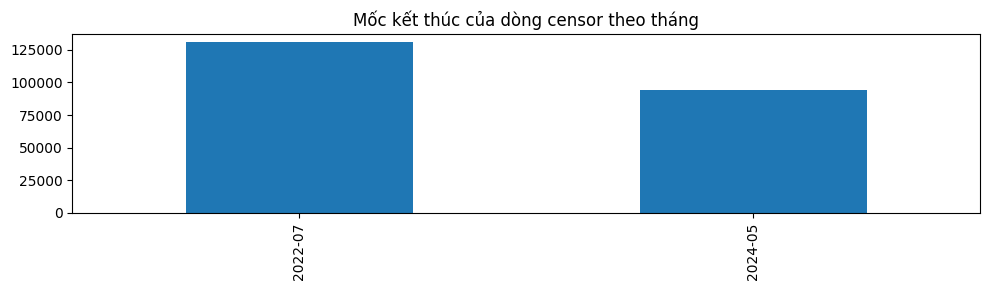

In [8]:
for name, df in [("train", train), ("test", test)]:
    t = pd.to_datetime(df["timestamp"], unit="s")
    print(f"{name}: {t.min():%Y-%m-%d} -> {t.max():%Y-%m-%d}")

cens = pd.concat([train, test])
cens = cens[cens["status"] == 0]
end = pd.to_datetime(cens["timestamp"] + cens["timeDiff"], unit="s")
print("\nMốc kết thúc của các dòng censor:")
print(end.describe())
print("Số ngày khác nhau:", end.dt.date.nunique())

end.dt.to_period("M").value_counts().sort_index().plot.bar(figsize=(10, 3), title="Mốc kết thúc của dòng censor theo tháng")
plt.tight_layout(); plt.show()

## 7. Tổng quan đặc trưng X

Phân loại cột theo nhóm, tìm cột toàn null / hằng số để bỏ khi huấn luyện.

In [9]:
def group_of(c):
    for p in ["user", "market"]:
        if c.startswith(p):
            return p
    if c.startswith(("sin", "cos")) or c in ["timeOfDay", "dayOfWeek", "dayOfMonth", "dayOfYear", "quarter", "dayOfQuarter", "isWeekend"]:
        return "time"
    if c.startswith("log"):
        return "log"
    return "base"


cols = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "% null": (X_train.isna().mean() * 100).round(1),
    "số giá trị khác nhau": X_train.nunique(dropna=True),
})
cols["nhóm"] = [group_of(c) for c in cols.index]
print(cols["nhóm"].value_counts())

ID_COLS = ["id", "user", "pool", "type", "timestamp"]
all_null = cols.index[cols["% null"] == 100].tolist()
constant = cols.index[(cols["số giá trị khác nhau"] <= 1) & (cols["% null"] < 100)].tolist()
print("\nCột định danh / không dùng:", ID_COLS)
print("Cột toàn null:", all_null)
print("Cột hằng số  :", constant)

DROP = sorted(set(ID_COLS + all_null + constant) - {"timestamp"})
FEATURES = [c for c in X_train.columns if c not in DROP + ["timestamp"]]
print(f"\n=> Giữ lại {len(FEATURES)} đặc trưng")
display(cols.loc[FEATURES].sort_values("nhóm"))

nhóm
user      46
market    37
base      24
time      19
log        3
Name: count, dtype: int64

Cột định danh / không dùng: ['id', 'user', 'pool', 'type', 'timestamp']
Cột toàn null: ['fromState', 'toState', 'liquidator', 'collateralAmount', 'collateralReserve', 'collateralAmountUSD', 'collateralAmountETH', 'borrowRateModeTo', 'borrowRateModeFrom', 'stableBorrowRate', 'variableBorrowRate', 'totalFee']
Cột hằng số  : ['type']

=> Giữ lại 112 đặc trưng


,dtype,% null,số giá trị khác nhau,nhóm
reserve,object,0.0,39,base
amount,float64,0.0,46641,base
amountUSD,float64,0.0,154367,base
amountETH,float64,0.0,136824,base
borrowRate,float64,0.0,161204,base
...,...,...,...,...
userWithdrawSumETH,float64,0.0,22051,user
userWithdrawAvgAmountUSD,float64,0.0,22087,user
userWithdrawSumUSD,float64,0.0,22084,user
userLiquidationAvgAmountUSD,float64,0.0,2467,user


In [10]:
cat_cols = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(X_train[c])]
print("Cột dạng chữ (cần mã hóa):", cat_cols)
for c in cat_cols:
    print(f"  {c}: {X_train[c].nunique()} giá trị, top 5 = {X_train[c].value_counts().head(5).to_dict()}")

Cột dạng chữ (cần mã hóa): ['reserve', 'borrowRateMode', 'coinType', 'userReserveMode', 'userCoinTypeMode', 'userIsNew', 'isWeekend']
  reserve: 39 giá trị, top 5 = {'USDC': 64384, 'USDT': 33948, 'DAI': 21501, 'WETH': 14911, 'WBTC': 3436}
  borrowRateMode: 2 giá trị, top 5 = {'Variable': 139695, 'Stable': 22131}
  coinType: 2 giá trị, top 5 = {'Stable': 130969, 'Non-Stable': 30857}
  userReserveMode: 39 giá trị, top 5 = {'USDC': 64384, 'USDT': 33948, 'DAI': 21501, 'WETH': 14911, 'WBTC': 3436}
  userCoinTypeMode: 2 giá trị, top 5 = {'Stable': 130969, 'Non-Stable': 30857}
  userIsNew: 2 giá trị, top 5 = {'FALSE': 158724, 'TRUE': 3102}
  isWeekend: 2 giá trị, top 5 = {'FALSE': 114057, 'TRUE': 47769}


## 8. Nhìn nhanh: tỷ lệ bị thanh lý sớm theo một vài đặc trưng

Chỉ dùng tập **train** để tránh nhìn trước dữ liệu test.

In [11]:
tr = train[train["label"].notna()].copy()
base_rate = tr["label"].mean()
print(f"Tỷ lệ lớp 1 chung (train): {100 * base_rate:.2f}%\n")

tr["từng bị thanh lý"] = np.where(tr["userLiquidationCount"] > 0, "có", "chưa")
for c in ["từng bị thanh lý", "coinType", "borrowRateMode", "userIsNew"]:
    if c in tr:
        g = tr.groupby(c)["label"].agg(["count", "mean"]).rename(columns={"count": "số dòng", "mean": "% lớp 1"})
        g["% lớp 1"] = (100 * g["% lớp 1"]).round(2)
        display(g)

top_res = tr["reserve"].value_counts().head(10).index
g = tr[tr["reserve"].isin(top_res)].groupby("reserve")["label"].agg(["count", "mean"])
g["mean"] = (100 * g["mean"]).round(2)
display(g.rename(columns={"count": "số dòng", "mean": "% lớp 1"}).sort_values("% lớp 1", ascending=False))

Tỷ lệ lớp 1 chung (train): 6.69%



,số dòng,% lớp 1
từng bị thanh lý,,
chưa,145850,3.74
có,18969,29.38


,số dòng,% lớp 1
coinType,,
Non-Stable,31128,3.15
Stable,133691,7.51


C:\Users\admin\AppData\Local\Temp\ipykernel_39500\2025440327.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = tr.groupby(c)["label"].agg(["count", "mean"]).rename(columns={"count": "số dòng", "mean": "% lớp 1"})


,số dòng,% lớp 1
borrowRateMode,,
Stable,22050,7.07
Variable,142769,6.63


C:\Users\admin\AppData\Local\Temp\ipykernel_39500\2025440327.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = tr.groupby(c)["label"].agg(["count", "mean"]).rename(columns={"count": "số dòng", "mean": "% lớp 1"})


,số dòng,% lớp 1
userIsNew,,
FALSE,160645,6.80
TRUE,4174,2.49


,số dòng,% lớp 1
reserve,,
DAI,22103,8.55
TUSD,1853,8.53
USDC,66240,7.50
USDT,34192,7.19
GUSD,2749,7.13
BUSD,2414,7.08
SUSD,2428,6.96
CRV,1800,2.06
WETH,14493,1.95


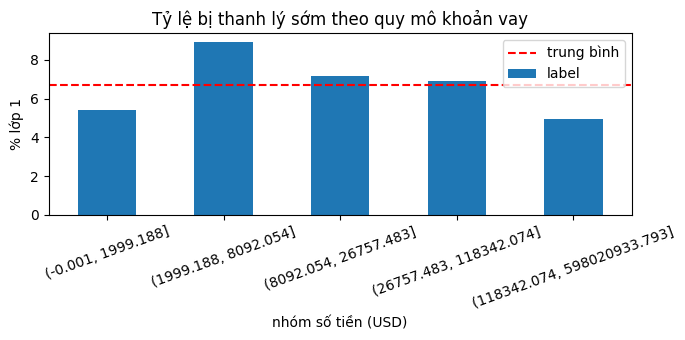

In [12]:
tr["nhóm số tiền (USD)"] = pd.qcut(tr["amountUSD"], 5, duplicates="drop")
g = tr.groupby("nhóm số tiền (USD)", observed=True)["label"].mean() * 100
ax = g.plot.bar(figsize=(7, 3.5), rot=20)
ax.axhline(100 * base_rate, color="red", ls="--", label="trung bình")
ax.set_ylabel("% lớp 1"); ax.set_title("Tỷ lệ bị thanh lý sớm theo quy mô khoản vay"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Lưu dữ liệu đã gắn nhãn

In [13]:
keep = FEATURES + ["id", "timestamp", "timeDiff", "status", "label"]
train_l = train.loc[train["label"].notna(), keep].reset_index(drop=True)
test_l = test.loc[test["label"].notna(), keep].reset_index(drop=True)
train_l["label"] = train_l["label"].astype(int)
test_l["label"] = test_l["label"].astype(int)

train_l.to_parquet(os.path.join(PROCESSED, "train_labeled.parquet"))
test_l.to_parquet(os.path.join(PROCESSED, "test_labeled.parquet"))
print("Đã lưu:", train_l.shape, test_l.shape)
print("-> processed/train_labeled.parquet, processed/test_labeled.parquet")

Đã lưu: (164819, 117) (99786, 117)
-> processed/train_labeled.parquet, processed/test_labeled.parquet


## Bước tiếp theo

Notebook sau sẽ dùng `train_labeled.parquet` / `test_labeled.parquet` để:
1. Huấn luyện Logistic Regression và XGBoost/LightGBM **không dùng PCA**, so với baseline AUC 0,72–0,75 của bài báo.
2. Hiệu chuẩn xác suất (reliability diagram, Brier score).
3. SHAP top đặc trưng.
4. Chia hạng A/B/C và tính tỷ lệ thanh lý thực tế theo hạng.